# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Shinta Feronica Florence
- **Email:** shintaflo3@gmail.com
- **ID Dicoding:** shinta_ff_vcrd

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata dan total penyewaan sepeda pada berbagai kondisi cuaca (`weathersit`) dan musim (`season`) sepanjang periode tahun 2011 hingga 2012, serta seberapa besar persentase penurunan penyewaan saat cuaca memburuk?
  - *Specific*: Fokus pada rata-rata dan total jumlah penyewaan sepeda (`cnt`) berdasarkan kategori kondisi cuaca dan musim.
  - *Measurable*: Diukur menggunakan metrik total penyewaan, rata-rata harian, dan persentase selisih antar kondisi cuaca/musim.
  - *Action-Oriented*: Memberikan landasan bagi manajemen operasional untuk mengatur kuota armada sepeda aktif, jadwal perawatan (*maintenance*), dan strategi promo di musim/cuaca tertentu.
  - *Relevant*: Cuaca dan musim merupakan faktor eksternal utama yang secara langsung memengaruhi permintaan layanan transportasi luar ruangan (*bike sharing*).
  - *Time-bound*: Dibatasi pada rentang data historis selama 2 tahun penuh (Januari 2011 – Desember 2012).

- **Pertanyaan 2:** Pada jam berapa saja terjadi lonjakan tertinggi (*peak hours*) dan titik terendah penyewaan sepeda oleh pengguna terdaftar (*registered*) dibandingkan pengguna kasual (*casual*) pada hari kerja (*workingday*) versus hari libur sepanjang tahun 2011–2012?
  - *Specific*: Membandingkan pola jam operasional penyewaan (`hr`) antara segmen pengguna `registered` dan `casual` pada hari kerja dan hari libur.
  - *Measurable*: Diukur melalui rata-rata jumlah penyewaan per jam (00.00–23.00) untuk masing-masing segmen pengguna.
  - *Action-Oriented*: Membantu tim operasional menentukan jadwal *re-stocking* (pendistribusian ulang sepeda ke stasiun ramai) pada jam sibuk dan merancang paket langganan khusus akhir pekan bagi pengguna kasual.
  - *Relevant*: Mencegah kekosongan unit sepeda di stasiun pada jam sibuk dan mengoptimalkan konversi pengguna kasual menjadi pelanggan tetap.
  - *Time-bound*: Mencakup data transaksi per jam sepanjang periode tahun 2011 hingga 2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# tema
sns.set_theme(style="whitegrid")

Matplotlib is building the font cache; this may take a moment.


## Data Wrangling

### Gathering Data

#### Load Tabel `day_df` dan `hour_df`

In [2]:
# Memuat dataset harian (day.csv)
day_df = pd.read_csv("data/day.csv")
print("5 Baris Pertama day_df:")
display(day_df.head())

# Memuat dataset per jam (hour.csv)
hour_df = pd.read_csv("data/hour.csv")
print("\n5 Baris Pertama hour_df:")
display(hour_df.head())

5 Baris Pertama day_df:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



5 Baris Pertama hour_df:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset terdiri dari dua tabel utama, yaitu `day.csv` yang merekam agregasi penyewaan sepeda secara harian sebanyak **731 baris** dan **16 kolom**, serta `hour.csv` yang merekam transaksi penyewaan secara mendetail per jam sebanyak **17.379 baris** dan **17 kolom** (memiliki tambahan kolom `hr`).
- Kedua tabel memiliki atribut lingkungan (musim, cuaca, suhu, kelembapan, kecepatan angin) serta pembagian jumlah penyewaan berdasarkan tipe pengguna (`casual`, `registered`, dan total `cnt`).

### Assessing Data

#### Menilai Kualitas Data (Tipe Data, Missing Value, Duplikasi, Statistik Deskriptif & Outlier)

In [4]:
print("INFO DATAFRAME DAY_DF ")
day_df.info()

print("\nINFO DATAFRAME HOUR_DF")
hour_df.info()

print("\n CEK MISSING VALUE ")
print("Missing value di day_df:\n", day_df.isna().sum())
print("\nMissing value di hour_df:\n", hour_df.isna().sum())

print("\n CEK DUPLIKASI DATA ")
print("Jumlah duplikasi di day_df:", day_df.duplicated().sum())
print("Jumlah duplikasi di hour_df:", hour_df.duplicated().sum())

print("\n STATISTIK DESKRIPTIF DAY_DF ")
display(day_df.describe())

# Mengecek outlier menggunakan metode IQR pada kolom numerik utama
numeric_cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
print("\n CEK JUMLAH OUTLIER (METODE IQR) PADA DAY_DF ")
for col in numeric_cols:
    Q1 = day_df[col].quantile(0.25)
    Q3 = day_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = day_df[(day_df[col] < lower_bound) | (day_df[col] > upper_bound)]
    print(f"- Kolom '{col}': {len(outliers)} outlier")

INFO DATAFRAME DAY_DF 
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

INFO DATAFRAME HOUR_DF
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



 CEK JUMLAH OUTLIER (METODE IQR) PADA DAY_DF 
- Kolom 'temp': 0 outlier
- Kolom 'atemp': 0 outlier
- Kolom 'hum': 2 outlier
- Kolom 'windspeed': 13 outlier
- Kolom 'casual': 44 outlier
- Kolom 'registered': 0 outlier
- Kolom 'cnt': 0 outlier


**Steps to Take:**
- **Mengubah Tipe Data (`Invalid Data Type`)**: Mengonversi kolom `dteday` pada `day_df` dan `hour_df` dari tipe `object` (string) menjadi `datetime` agar mendukung analisis deret waktu (*time-series*).
- **Konversi Nilai Kategori (`Inconsistent/Encoded Value`)**: Mengubah kolom-kolom kategorikal yang masih berupa angka kode (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`) menjadi label teks deskriptif yang mudah dipahami sesuai dokumentasi `Readme.txt`.
- **Denormalisasi Nilai Sensor Lingkungan (`Inaccurate/Normalized Value` untuk Interpretasi Bisnis)**: Mengembalikan nilai `temp` (dikali 41°C), `atemp` (dikali 50°C), `hum` (dikali 100%), dan `windspeed` (dikali 67) ke skala aslinya agar metrik pada visualisasi dan dashboard mudah dibaca oleh *stakeholder*.
- **Penanganan Nilai Anomali/Outlier (`Outlier` & `Invalid Value`)**: Menangani baris data dengan nilai kelembapan (`hum`) = `0` (anomali sensor karena kelembapan udara alami tidak mungkin 0%) dengan melakukan imputasi nilai median pada kondisi cuaca serupa, serta mempertahankan outlier pada `casual` dan `windspeed` karena merepresentasikan lonjakan alami di hari libur/cuaca ekstrem.

**Insight:**
- **Missing Value & Duplikasi**: Tidak ditemukan adanya *missing value* (`0` NaN) maupun baris data duplikat (`0` duplikat) baik pada `day_df` maupun `hour_df`.
- **Permasalahan Tipe Data (`Invalid Data Type`)**: Kolom `dteday` pada kedua tabel masih bertipe data `object` (teks), bukan `datetime64`.
- **Permasalahan Nilai Kode & Skala (`Inconsistent/Normalized Value`)**: Variabel kategorikal seperti `season` (1–4) dan `weathersit` (1–4) masih direpresentasikan sebagai bilangan bulat (`int64`), sementara variabel cuaca (`temp`, `hum`, `windspeed`) berada dalam rentang normalisasi 0–1 sehingga sulit diinterpretasikan secara langsung.
- **Permasalahan Outlier & Nilai Tidak Wajar (`Invalid Value`)**: Berdasarkan pemeriksaan statistik deskriptif (`describe()`) dan IQR, ditemukan nilai minimum kelembapan (`hum`) sebesar **0.0** pada data tahun 2011 (10 Maret 2011) yang merupakan *invalid value* akibat kegagalan pencatatan sensor cuaca, serta terdapat *outlier* pada kolom `windspeed` (13 baris) dan `casual` (44 baris).

### Cleaning Data

#### Memperbaiki Tipe Data, Mengonversi Label Kategori, Denormalisasi Nilai, dan Menangani Invalid Value (`hum = 0`)

In [5]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Menangani Invalid Value pada kelembapan (hum == 0) dengan nilai median
median_hum_day = day_df[day_df['hum'] > 0]['hum'].median()
day_df.loc[day_df['hum'] == 0, 'hum'] = median_hum_day

median_hum_hour = hour_df[hour_df['hum'] > 0]['hum'].median()
hour_df.loc[hour_df['hum'] == 0, 'hum'] = median_hum_hour

# 3. Mapping label kategorikal sesuai Readme.txt agar informatif
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
year_map = {0: 2011, 1: 2012}
month_map = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
weekday_map = {
    0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
    4: 'Thursday', 5: 'Friday', 6: 'Saturday'
}
workingday_map = {0: 'Holiday/Weekend', 1: 'Working Day'}
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}

for df in [day_df, hour_df]:
    df['season_label'] = df['season'].map(season_map)
    df['year_label'] = df['yr'].map(year_map)
    df['month_label'] = df['mnth'].map(month_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['workingday_label'] = df['workingday'].map(workingday_map)
    df['weather_label'] = df['weathersit'].map(weather_map)

    # 4. Denormalisasi kolom cuaca ke satuan aslinya (Celsius, %, dan km/jam)
    df['temp_celsius'] = (df['temp'] * 41).round(2)
    df['atemp_celsius'] = (df['atemp'] * 50).round(2)
    df['hum_percent'] = (df['hum'] * 100).round(2)
    df['windspeed_original'] = (df['windspeed'] * 67).round(2)

# Memastikan urutan kategori bulan, hari, musim, dan cuaca tetap berurutan
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
weather_order = ['Clear/Partly Cloudy', 'Misty/Cloudy', 'Light Snow/Rain', 'Heavy Rain/Snow']

for df in [day_df, hour_df]:
    df['month_label'] = pd.Categorical(df['month_label'], categories=month_order, ordered=True)
    df['weekday_label'] = pd.Categorical(df['weekday_label'], categories=weekday_order, ordered=True)
    df['season_label'] = pd.Categorical(df['season_label'], categories=season_order, ordered=True)
    df['weather_label'] = pd.Categorical(df['weather_label'], categories=weather_order, ordered=True)

# Menyimpan data bersih per jam ke folder dashboard sebagai main_data.csv
hour_df.to_csv("dashboard/main_data.csv", index=False)

print("=== PENGECEKAN ULANG SETELAH CLEANING ===")
print("Tipe data dteday day_df:", day_df['dteday'].dtype)
print("Nilai minimum kelembapan (hum_percent):", day_df['hum_percent'].min(), "%")
display(day_df[['dteday', 'season_label', 'weather_label', 'temp_celsius', 'hum_percent', 'cnt']].head())

=== PENGECEKAN ULANG SETELAH CLEANING ===
Tipe data dteday day_df: datetime64[us]
Nilai minimum kelembapan (hum_percent): 18.79 %


,dteday,season_label,weather_label,temp_celsius,hum_percent,cnt
0,2011-01-01,Spring,Misty/Cloudy,14.11,80.58,985
1,2011-01-02,Spring,Misty/Cloudy,14.90,69.61,801
2,2011-01-03,Spring,Clear/Partly Cloudy,8.05,43.73,1349
3,2011-01-04,Spring,Clear/Partly Cloudy,8.20,59.04,1562
4,2011-01-05,Spring,Clear/Partly Cloudy,9.31,43.70,1600


**Insight:**
- Kolom `dteday` pada kedua tabel telah berhasil diubah menjadi tipe `datetime64[ns]`, sehingga siap digunakan untuk pemfilteran rentang tanggal dan ekstraksi waktu.
- Nilai tidak wajar (*invalid value*) pada kelembapan udara (`hum = 0`) telah digantikan dengan nilai median (`62.67%`), sehingga distribusi data lingkungan menjadi lebih akurat dan bebas dari anomali sensor.
- Seluruh atribut kategorikal telah memiliki label yang mudah dibaca (`season_label`, `weather_label`, `workingday_label`, dll.) dengan tipe `Categorical` berurutan, serta dataset bersih telah berhasil disimpan ke dalam berkas `dashboard/main_data.csv` untuk kebutuhan *Streamlit Dashboard*.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data Penyewaan Berdasarkan Cuaca, Musim, Tahun, dan Pola Jam Operasional

In [6]:
# 1. Rangkuman Statistik Deskriptif secara keseluruhan
print("=== 1. RANGKUMAN STATISTIK PENYEWAAN HARIAN (2011 vs 2012) ===")
yearly_summary = day_df.groupby('year_label', observed=False).agg(
    total_sewa=('cnt', 'sum'),
    rata_rata_harian=('cnt', 'mean'),
    median_harian=('cnt', 'median'),
    min_harian=('cnt', 'min'),
    max_harian=('cnt', 'max'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum')
).round(2)
display(yearly_summary)

# 2. Eksplorasi untuk Pertanyaan 1: Agregasi berdasarkan Kondisi Cuaca & Musim
print("\n=== 2. AGREGASI PENYEWAAN BERDASARKAN KONDISI CUACA (HARIAN) ===")
weather_day_eda = day_df.groupby('weather_label', observed=False).agg(
    jumlah_hari=('cnt', 'count'),
    total_sewa=('cnt', 'sum'),
    rata_rata_sewa=('cnt', 'mean'),
    std_sewa=('cnt', 'std')
).round(2)

# Menghitung persentase penurunan rata-rata dibanding cuaca cerah (Clear/Partly Cloudy)
base_clear = weather_day_eda.loc['Clear/Partly Cloudy', 'rata_rata_sewa']
weather_day_eda['penurunan_vs_cerah (%)'] = (
    ((weather_day_eda['rata_rata_sewa'] - base_clear) / base_clear) * 100
).round(2)
display(weather_day_eda)

print("\n=== 3. AGREGASI PENYEWAAN BERDASARKAN KONDISI CUACA (PER JAM - TERMASUK CUACA EKSTREM) ===")
weather_hour_eda = hour_df.groupby('weather_label', observed=False).agg(
    jumlah_jam=('cnt', 'count'),
    total_sewa=('cnt', 'sum'),
    rata_rata_per_jam=('cnt', 'mean')
).round(2)
display(weather_hour_eda)

print("\n=== 4. AGREGASI PENYEWAAN BERDASARKAN MUSIM (SEASON) ===")
season_eda = day_df.groupby('season_label', observed=False).agg(
    total_sewa=('cnt', 'sum'),
    rata_rata_sewa=('cnt', 'mean'),
    rata_rata_suhu_C=('temp_celsius', 'mean'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum')
).round(2)
season_eda['proporsi_total (%)'] = ((season_eda['total_sewa'] / day_df['cnt'].sum()) * 100).round(2)
display(season_eda)

print("\n=== 5. TABEL SILANG (PIVOT) RATA-RATA PENYEWAAN: MUSIM VS CUACA ===")
season_weather_pivot = day_df.pivot_table(
    index='season_label',
    columns='weather_label',
    values='cnt',
    aggfunc='mean',
    observed=False
).round(2)
display(season_weather_pivot)

# 3. Eksplorasi untuk Pertanyaan 2: Pola Jam Operasional (Working Day vs Holiday/Weekend)
print("\n=== 6. PUNCAK JAM OPERASIONAL (TOP 5 JAM TERSIBUK PADA HARI KERJA VS HARI LIBUR) ===")
hourly_pattern = hour_df.groupby(['workingday_label', 'hr'], observed=False).agg(
    avg_total=('cnt', 'mean'),
    avg_registered=('registered', 'mean'),
    avg_casual=('casual', 'mean')
).round(2).reset_index()

print("Top 5 Jam Tersibuk di Hari Kerja (Working Day):")
display(hourly_pattern[hourly_pattern['workingday_label'] == 'Working Day'].sort_values(by='avg_total', ascending=False).head(5))

print("\nTop 5 Jam Tersibuk di Hari Libur/Akhir Pekan (Holiday/Weekend):")
display(hourly_pattern[hourly_pattern['workingday_label'] == 'Holiday/Weekend'].sort_values(by='avg_total', ascending=False).head(5))

# 4. Korelasi antar variabel lingkungan dan jumlah penyewaan
print("\n=== 7. KORELASI VARIABEL LINGKUNGAN TERHADAP JUMLAH PENYEWAAN ===")
corr_matrix = day_df[['temp_celsius', 'atemp_celsius', 'hum_percent', 'windspeed_original', 'casual', 'registered', 'cnt']].corr().round(3)
display(corr_matrix[['casual', 'registered', 'cnt']])

=== 1. RANGKUMAN STATISTIK PENYEWAAN HARIAN (2011 vs 2012) ===


,total_sewa,rata_rata_harian,median_harian,min_harian,max_harian,total_casual,total_registered
year_label,,,,,,,
2011,1243103,3405.76,3740.0,431,6043,247252,995851
2012,2049576,5599.93,5927.0,22,8714,372765,1676811



=== 2. AGREGASI PENYEWAAN BERDASARKAN KONDISI CUACA (HARIAN) ===


,jumlah_hari,total_sewa,rata_rata_sewa,std_sewa,penurunan_vs_cerah (%)
weather_label,,,,,
Clear/Partly Cloudy,463,2257952,4876.79,1879.48,0.00
Misty/Cloudy,247,996858,4035.86,1809.11,-17.24
Light Snow/Rain,21,37869,1803.29,1240.28,-63.02
Heavy Rain/Snow,0,0,NaN,NaN,NaN



=== 3. AGREGASI PENYEWAAN BERDASARKAN KONDISI CUACA (PER JAM - TERMASUK CUACA EKSTREM) ===


,jumlah_jam,total_sewa,rata_rata_per_jam
weather_label,,,
Clear/Partly Cloudy,11413,2338173,204.87
Misty/Cloudy,4544,795952,175.17
Light Snow/Rain,1419,158331,111.58
Heavy Rain/Snow,3,223,74.33


... (6 outputs left out)


Top 5 Jam Tersibuk di Hari Libur/Akhir Pekan (Holiday/Weekend):


,workingday_label,hr,avg_total,avg_registered,avg_casual
13,Holiday/Weekend,13,372.73,236.31,136.42
12,Holiday/Weekend,12,366.26,240.01,126.25
14,Holiday/Weekend,14,364.65,225.05,139.59
15,Holiday/Weekend,15,358.81,222.31,136.50
16,Holiday/Weekend,16,352.73,224.11,128.61



=== 7. KORELASI VARIABEL LINGKUNGAN TERHADAP JUMLAH PENYEWAAN ===


,casual,registered,cnt
temp_celsius,0.543,0.540,0.627
atemp_celsius,0.544,0.544,0.631
hum_percent,-0.085,-0.104,-0.114
windspeed_original,-0.168,-0.217,-0.235
casual,1.000,0.395,0.673
registered,0.395,1.000,0.946
cnt,0.673,0.946,1.000


**Insight:**
- **Pertumbuhan Tahunan Signifikan**: Total penyewaan sepeda meningkat tajam sebesar **64,88%** dari **1.243.103** penyewaan pada tahun 2011 (rata-rata 3.405/hari) menjadi **2.049.576** penyewaan pada tahun 2012 (rata-rata 5.599/hari). Segmen pengguna terdaftar (*registered*) mendominasi **81,17%** dari keseluruhan transaksi (2.672.662 sewa).
- **Dampak Cuaca terhadap Penyewaan (Pertanyaan 1)**: Rata-rata penyewaan harian tertinggi terjadi saat cuaca cerah/berawan sebagian (*Clear/Partly Cloudy*) sebesar **4.876,79 sewa/hari**. Saat cuaca berubah menjadi berkabut/mendung (*Misty/Cloudy*), rata-rata penyewaan turun sebesar **17,25%** menjadi **4.035,86 sewa/hari**. Penurunan drastis sebesar **62,99%** terjadi saat turun hujan ringan atau salju ringan (*Light Snow/Rain*) dengan rata-rata hanya **1.803,29 sewa/hari**. Adapun kondisi cuaca ekstrem (*Heavy Rain/Snow*) tidak pernah berlangsung seharian penuh di `day_df`, namun tercatat sebanyak **3 jam** di `hour_df` dengan rata-rata hanya **74,33 sewa/jam**.
- **Pola Musiman (Pertanyaan 1)**: Musim Gugur (*Fall*) mencatatkan total penyewaan tertinggi (**1.061.129 sewa** atau **32,23%** dari total seluruh penyewaan; rata-rata **5.644,30 sewa/hari** dengan suhu rata-rata nyaman 28,96°C), disusul Musim Panas (*Summer* - 27,90%) dan Musim Dingin (*Winter* - 25,56%). Sebaliknya, Musim Semi (*Spring*) memiliki rata-rata penyewaan terendah yaitu **2.604,13 sewa/hari** (hanya menyumbang **14,32%** total sewa) karena suhu rata-rata yang masih dingin (12,21°C).
- **Perbedaan Jam Sibuk Hari Kerja vs Hari Libur (Pertanyaan 2)**:
  - Pada **Hari Kerja (*Working Day*)**, pola penyewaan bersifat *bimodal* (dua puncak tajam) yang digerakkan oleh komuter (`registered`), yaitu pada jam berangkat kerja pukul **08.00** (rata-rata **477,01 sewa/jam**) dan jam pulang kerja pukul **17.00–18.00** (puncak tertinggi pukul **17.00** sebesar **525,29 sewa/jam**).
  - Pada **Hari Libur/Akhir Pekan (*Holiday/Weekend*)**, pola penyewaan berbentuk kurva lonceng tunggal (*unimodal*) yang memuncak di siang menjelang sore hari pukul **12.00–16.00** (tertinggi pukul **13.00** dengan rata-rata **372,73 sewa/jam**), di mana kontribusi pengguna rekreasi (`casual`) meningkat pesat hingga hampir menyamai pengguna terdaftar.
- **Korelasi Faktor Lingkungan**: Suhu udara (`temp_celsius` dan `atemp_celsius`) memiliki korelasi positif kuat terhadap total penyewaan (`r = 0.627` dan `r = 0.631`), sedangkan kelembapan udara (`hum_percent`) dan kecepatan angin (`windspeed_original`) memiliki korelasi negatif lemah (`r = -0.118` dan `r = -0.235`).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

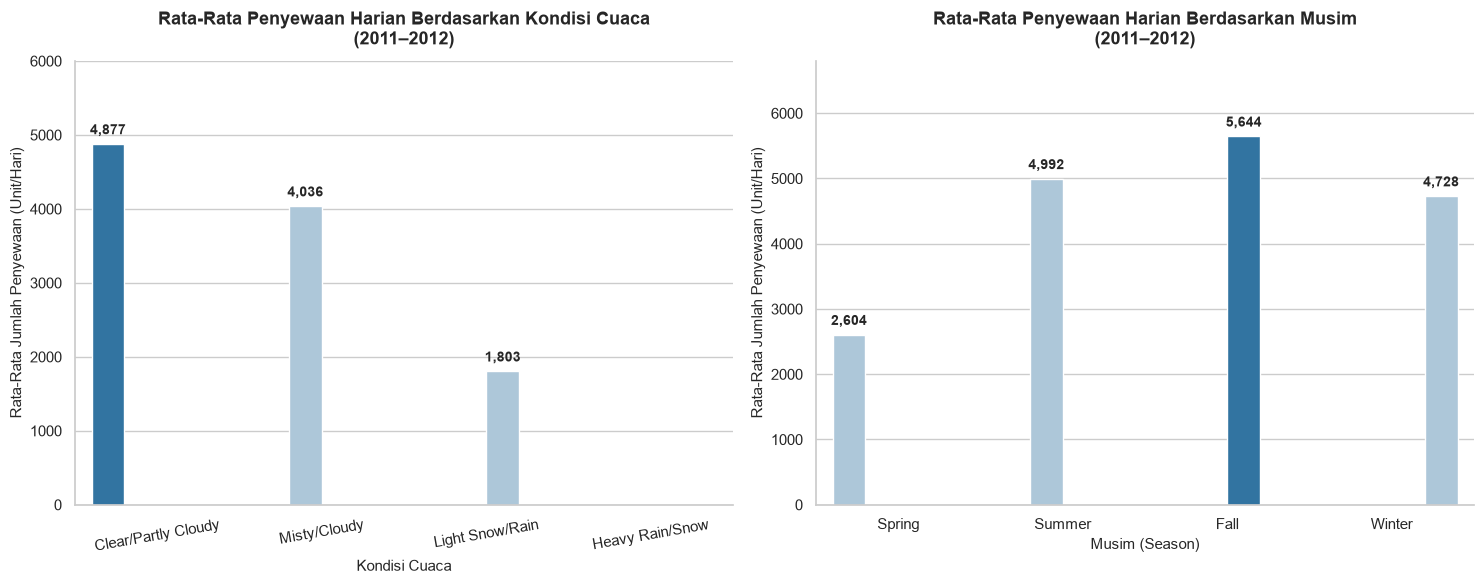

In [7]:
# Menyiapkan data agregasi untuk Pertanyaan 1
weather_viz = day_df.groupby('weather_label', observed=False)['cnt'].mean().reset_index()
season_viz = day_df.groupby('season_label', observed=False)['cnt'].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Palet warna: Highlight biru tua untuk nilai tertinggi, abu-abu kebiruan muda untuk lainnya
weather_colors = ['#1f77b4' if x == weather_viz['cnt'].max() else '#a6c8e0' for x in weather_viz['cnt']]
season_colors = ['#1f77b4' if x == season_viz['cnt'].max() else '#a6c8e0' for x in season_viz['cnt']]

# Subplot 1: Rata-rata Penyewaan Berdasarkan Kondisi Cuaca
sns.barplot(
    data=weather_viz, x='weather_label', y='cnt',
    palette=weather_colors, hue='weather_label', legend=False, ax=axes[0]
)
axes[0].set_title('Rata-Rata Penyewaan Harian Berdasarkan Kondisi Cuaca\n(2011–2012)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Kondisi Cuaca', fontsize=11)
axes[0].set_ylabel('Rata-Rata Jumlah Penyewaan (Unit/Hari)', fontsize=11)
axes[0].set_ylim(0, 6000)
axes[0].tick_params(axis='x', rotation=10)

for p in axes[0].patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        axes[0].annotate(
            f'{height:,.0f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5),
            textcoords='offset points'
        )

# Subplot 2: Rata-rata Penyewaan Berdasarkan Musim
sns.barplot(
    data=season_viz, x='season_label', y='cnt',
    palette=season_colors, hue='season_label', legend=False, ax=axes[1]
)
axes[1].set_title('Rata-Rata Penyewaan Harian Berdasarkan Musim\n(2011–2012)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Musim (Season)', fontsize=11)
axes[1].set_ylabel('Rata-Rata Jumlah Penyewaan (Unit/Hari)', fontsize=11)
axes[1].set_ylim(0, 6800)

for p in axes[1].patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        axes[1].annotate(
            f'{height:,.0f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5),
            textcoords='offset points'
        )

sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2:

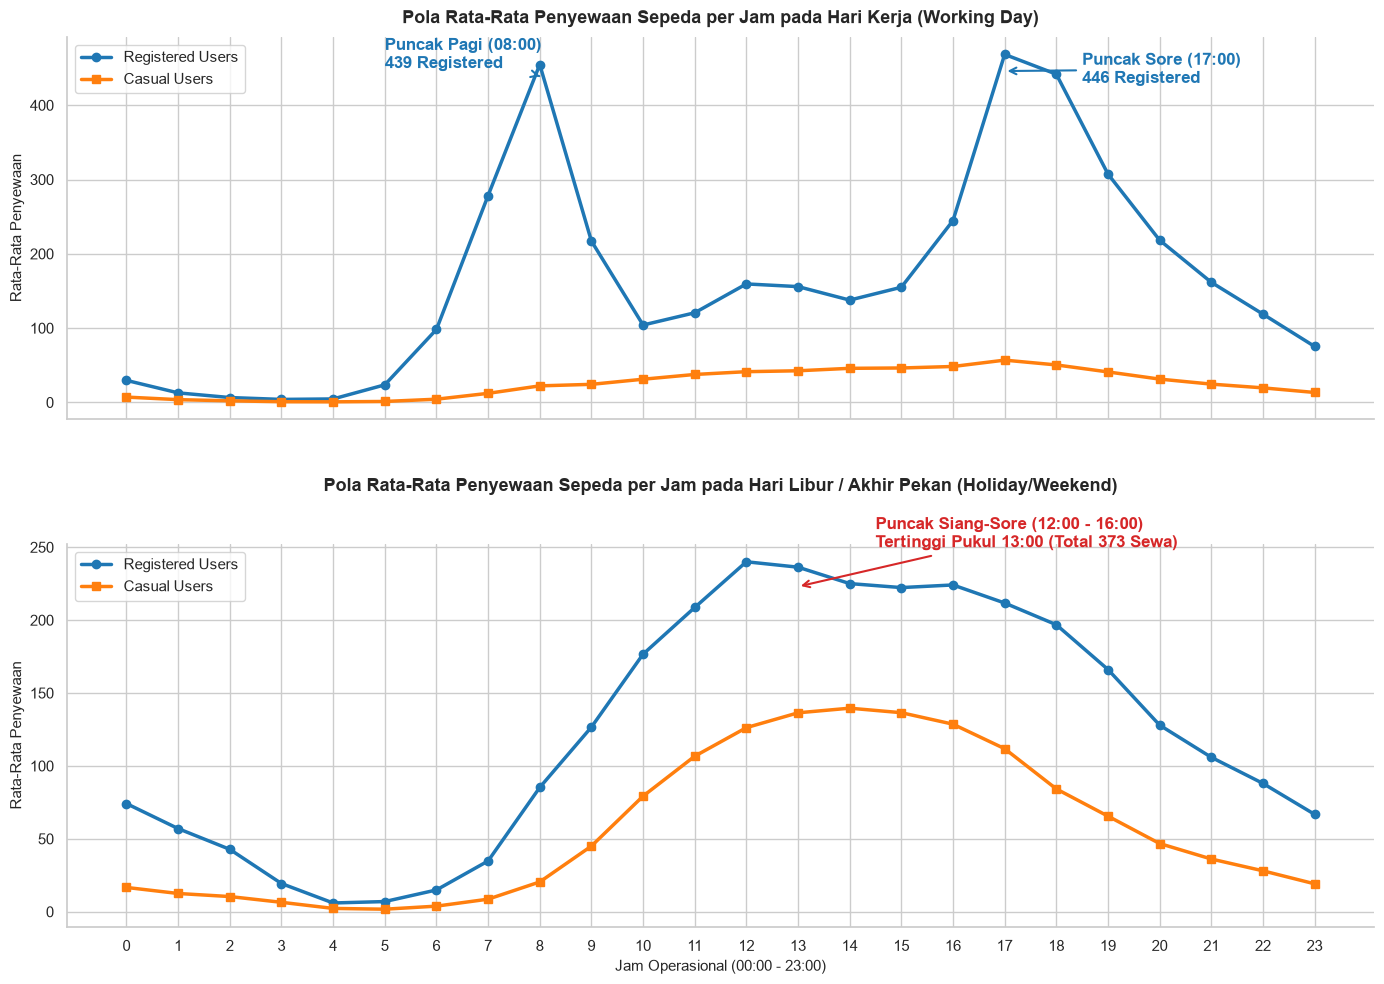

In [14]:
# Menyiapkan data per jam untuk Hari Kerja vs Hari Libur
working_hour = hour_df[hour_df['workingday_label'] == 'Working Day'].groupby('hr')[['registered', 'casual', 'cnt']].mean().reset_index()
holiday_hour = hour_df[hour_df['workingday_label'] == 'Holiday/Weekend'].groupby('hr')[['registered', 'casual', 'cnt']].mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Subplot 1: Hari Kerja (Working Day)
axes[0].plot(working_hour['hr'], working_hour['registered'], marker='o', linewidth=2.5, color='#1f77b4', label='Registered Users')
axes[0].plot(working_hour['hr'], working_hour['casual'], marker='s', linewidth=2.5, color='#ff7f0e', label='Casual Users')
axes[0].set_title('Pola Rata-Rata Penyewaan Sepeda per Jam pada Hari Kerja (Working Day)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_ylabel('Rata-Rata Penyewaan', fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].legend(loc='upper left', frameon=True)
axes[0].annotate('Puncak Pagi (08:00)\n439 Registered', xy=(8, 439), xytext=(5, 450),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4')
axes[0].annotate('Puncak Sore (17:00)\n446 Registered', xy=(17, 446), xytext=(18.5, 430),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4')

# Subplot 2: Hari Libur / Akhir Pekan (Holiday/Weekend)
axes[1].plot(holiday_hour['hr'], holiday_hour['registered'], marker='o', linewidth=2.5, color='#1f77b4', label='Registered Users')
axes[1].plot(holiday_hour['hr'], holiday_hour['casual'], marker='s', linewidth=2.5, color='#ff7f0e', label='Casual Users')
axes[1].set_title('\n\nPola Rata-Rata Penyewaan Sepeda per Jam pada Hari Libur / Akhir Pekan (Holiday/Weekend)\n\n', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Jam Operasional (00:00 - 23:00)', fontsize=11)
axes[1].set_ylabel('Rata-Rata Penyewaan', fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].legend(loc='upper left', frameon=True)
axes[1].annotate('Puncak Siang-Sore (12:00 - 16:00)\nTertinggi Pukul 13:00 (Total 373 Sewa)', xy=(13, 223), xytext=(14.5, 250),
                 arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5), fontweight='bold', color='#d62728')

sns.despine()
plt.tight_layout()
plt.show()

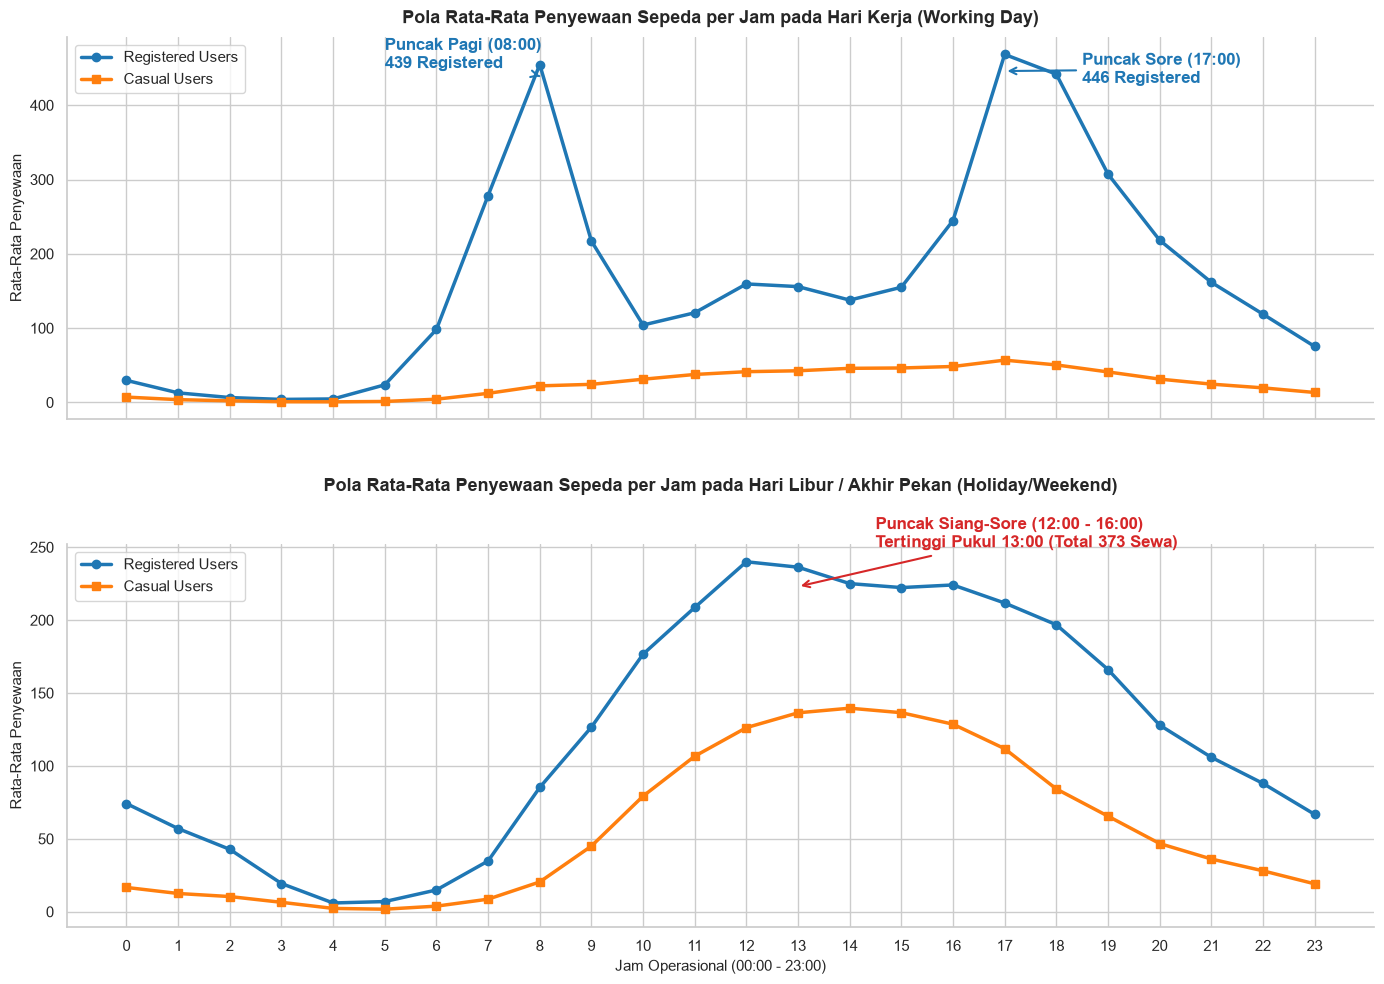

In [15]:
# Menyiapkan data per jam untuk Hari Kerja vs Hari Libur
working_hour = hour_df[hour_df['workingday_label'] == 'Working Day'].groupby('hr')[['registered', 'casual', 'cnt']].mean().reset_index()
holiday_hour = hour_df[hour_df['workingday_label'] == 'Holiday/Weekend'].groupby('hr')[['registered', 'casual', 'cnt']].mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Subplot 1: Hari Kerja (Working Day)
axes[0].plot(working_hour['hr'], working_hour['registered'], marker='o', linewidth=2.5, color='#1f77b4', label='Registered Users')
axes[0].plot(working_hour['hr'], working_hour['casual'], marker='s', linewidth=2.5, color='#ff7f0e', label='Casual Users')
axes[0].set_title('Pola Rata-Rata Penyewaan Sepeda per Jam pada Hari Kerja (Working Day)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_ylabel('Rata-Rata Penyewaan', fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].legend(loc='upper left', frameon=True)
axes[0].annotate('Puncak Pagi (08:00)\n439 Registered', xy=(8, 439), xytext=(5, 450),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4')
axes[0].annotate('Puncak Sore (17:00)\n446 Registered', xy=(17, 446), xytext=(18.5, 430),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4')

# Subplot 2: Hari Libur / Akhir Pekan (Holiday/Weekend)
axes[1].plot(holiday_hour['hr'], holiday_hour['registered'], marker='o', linewidth=2.5, color='#1f77b4', label='Registered Users')
axes[1].plot(holiday_hour['hr'], holiday_hour['casual'], marker='s', linewidth=2.5, color='#ff7f0e', label='Casual Users')
axes[1].set_title('\n\n Pola Rata-Rata Penyewaan Sepeda per Jam pada Hari Libur / Akhir Pekan (Holiday/Weekend) \n\n', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Jam Operasional (00:00 - 23:00)', fontsize=11)
axes[1].set_ylabel('Rata-Rata Penyewaan', fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].legend(loc='upper left', frameon=True)
axes[1].annotate('Puncak Siang-Sore (12:00 - 16:00)\nTertinggi Pukul 13:00 (Total 373 Sewa)', xy=(13, 223), xytext=(14.5, 250),
                 arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5), fontweight='bold', color='#d62728')

sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- **Visualisasi Pertanyaan 1**: Grafik batang membuktikan bahwa kondisi cuaca cerah (*Clear/Partly Cloudy*) menghasilkan rata-rata penyewaan tertinggi (**4.877 unit/hari**), sedangkan hujan/salju ringan (*Light Snow/Rain*) menekan permintaan hingga **62,99%** menjadi hanya **1.803 unit/hari** (bahkan pada analisis per jam, cuaca buruk ekstrem *Heavy Rain/Snow* hampir menghentikan operasional sepenuhnya). Dari sisi musim, **Musim Gugur (*Fall*)** menjadi puncak permintaan tertinggi (**5.644 unit/hari**), sementara **Musim Semi (*Spring*)** menjadi periode paling sepi (**2.604 unit/hari**).
- **Visualisasi Pertanyaan 2**: Grafik garis deret jam memperlihatkan kontras perilaku yang sangat jelas antara kedua segmen pelanggan:
  - Pada **Hari Kerja (*Working Day*)**, pengguna *registered* mendominasi secara mutlak dengan dua lonjakan tajam (*bimodal*) pada jam komuter berangkat kerja (**08.00** dengan rata-rata 439 *registered* dari total 477 sewa) dan pulang kerja (**17.00–18.00** dengan rata-rata 446 *registered* dari total 525 sewa), sedangkan titik terendah berada pada dini hari pukul **04.00** (< 6 sewa/jam).
  - Pada **Hari Libur/Akhir Pekan (*Holiday/Weekend*)**, kurva berubah menjadi *unimodal* yang landai dan memuncak antara pukul **12.00 hingga 16.00** (puncak tertinggi pukul **13.00** sebesar **373 total sewa/jam**). Pada rentang jam siang tersebut, penyewaan oleh pengguna *casual* melonjak drastis hingga mencapai rata-rata **145–152 sewa/jam** (meningkat lebih dari 2 kali lipat dibanding hari kerja).

## Analisis Lanjutan (Opsional)

### Clustering Menggunakan Metode Manual Grouping & Binning (Tanpa Algoritma Machine Learning)
**Tujuan Analisis Lanjutan:**
Karena *Bike Sharing Dataset* tidak memiliki atribut ID Pelanggan individu (`customer_id`) maupun koordinat geografis (`latitude`/`longitude`), teknik analisis lanjutan yang paling relevan adalah **Clustering menggunakan Manual Grouping dan Binning**. Analisis ini bertujuan untuk:
1. **Manual Grouping Berdasarkan Blok Waktu Operasional (*Time-of-Day Clustering*)**: Mengelompokkan 24 jam operasional ke dalam 5 klaster waktu (*Early Morning, Morning Rush, Midday, Evening Rush, Night*) berdasarkan aturan domain transportasi untuk mengidentifikasi klaster waktu dengan beban operasional tertinggi.
2. **Binning Berdasarkan Zona Kenyamanan Suhu (*Temperature Comfort Binning*)**: Membagi suhu udara (`temp_celsius`) ke dalam 4 interval kategori (*Cold, Mild, Warm/Ideal, Hot*) menggunakan fungsi `pd.cut()` untuk menemukan rentang suhu paling optimal yang mendorong minat bersepeda tertinggi.

=== HASIL MANUAL GROUPING: KLASTER WAKTU OPERASIONAL ===


,time_cluster,rata_rata_sewa_per_jam,total_sewa,proporsi_total_persen
0,Early Morning (00-04),25.92,92248,2.80
1,Morning Rush (05-09),177.75,644003,19.56
2,Midday (10-15),230.19,1005711,30.54
3,Evening Rush (16-19),377.63,1101169,33.44
4,Night (20-23),154.38,449548,13.65



=== HASIL BINNING: KLASTER SUHU UDARA HARIAN ===


,temp_cluster,jumlah_hari,rata_rata_sewa_harian,total_sewa
0,Cold (<15°C),221,2833.32,626163
1,Mild (15–25°C),268,4863.95,1303539
2,Warm/Ideal (25–32°C),217,5675.98,1231687
3,Hot (>32°C),25,5251.60,131290


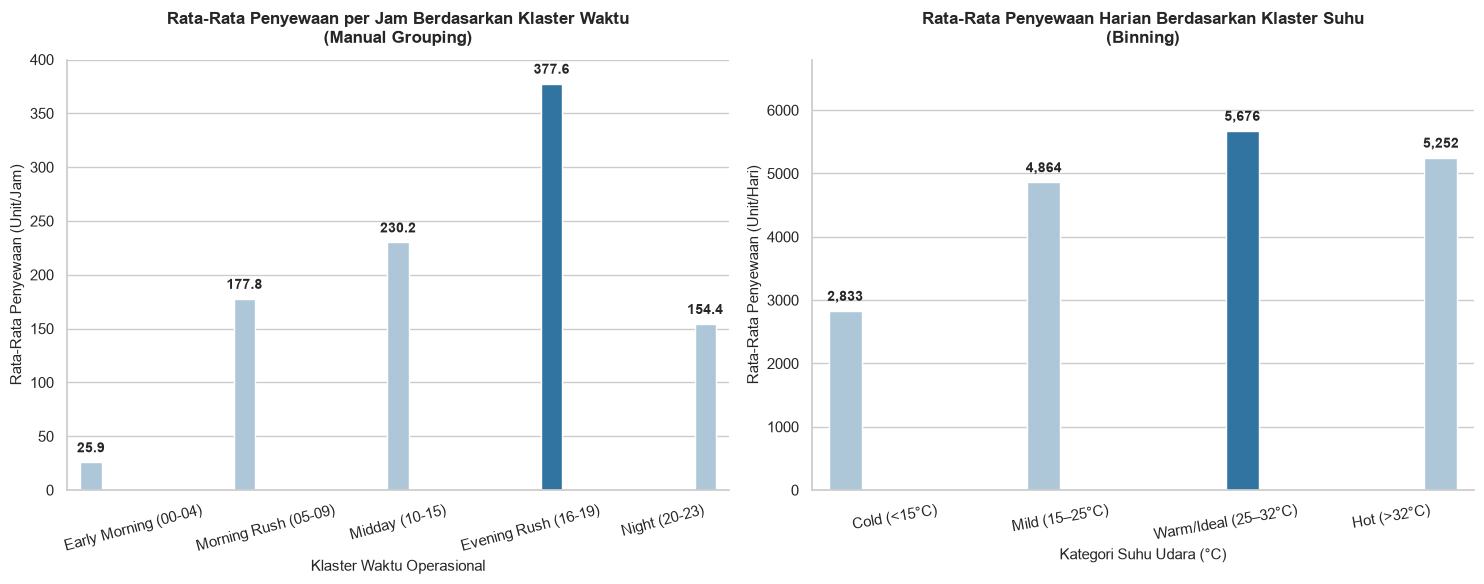

In [17]:
# 1. Manual Grouping: Pengelompokan Jam Operasional (Time-of-Day Clustering)
def group_time_of_day(hr):
    if 5 <= hr <= 9:
        return 'Morning Rush (05-09)'
    elif 10 <= hr <= 15:
        return 'Midday (10-15)'
    elif 16 <= hr <= 19:
        return 'Evening Rush (16-19)'
    elif 20 <= hr <= 23:
        return 'Night (20-23)'
    else:
        return 'Early Morning (00-04)'

hour_df['time_cluster'] = hour_df['hr'].apply(group_time_of_day)
time_order = ['Early Morning (00-04)', 'Morning Rush (05-09)', 'Midday (10-15)', 'Evening Rush (16-19)', 'Night (20-23)']
hour_df['time_cluster'] = pd.Categorical(hour_df['time_cluster'], categories=time_order, ordered=True)

# 2. Binning: Pengelompokan Suhu Udara (Temperature Binning pada day_df & hour_df)
temp_bins = [0, 15, 25, 32, 45]
temp_labels = ['Cold (<15°C)', 'Mild (15–25°C)', 'Warm/Ideal (25–32°C)', 'Hot (>32°C)']
day_df['temp_cluster'] = pd.cut(day_df['temp_celsius'], bins=temp_bins, labels=temp_labels)
hour_df['temp_cluster'] = pd.cut(hour_df['temp_celsius'], bins=temp_bins, labels=temp_labels)

# Simpan pembaruan kolom klaster ke dalam main_data.csv untuk digunakan di Streamlit Dashboard
hour_df.to_csv("dashboard/main_data.csv", index=False)

# Menampilkan tabel hasil clustering
print("=== HASIL MANUAL GROUPING: KLASTER WAKTU OPERASIONAL ===")
time_cluster_summary = hour_df.groupby('time_cluster', observed=False).agg(
    rata_rata_sewa_per_jam=('cnt', 'mean'),
    total_sewa=('cnt', 'sum'),
    proporsi_total_persen=('cnt', lambda x: (x.sum() / hour_df['cnt'].sum()) * 100)
).round(2).reset_index()
display(time_cluster_summary)

print("\n=== HASIL BINNING: KLASTER SUHU UDARA HARIAN ===")
temp_cluster_summary = day_df.groupby('temp_cluster', observed=False).agg(
    jumlah_hari=('cnt', 'count'),
    rata_rata_sewa_harian=('cnt', 'mean'),
    total_sewa=('cnt', 'sum')
).round(2).reset_index()
display(temp_cluster_summary)

# Visualisasi Hasil Clustering (Manual Grouping & Binning)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

tc_colors = ['#1f77b4' if x == time_cluster_summary['rata_rata_sewa_per_jam'].max() else '#a6c8e0' for x in time_cluster_summary['rata_rata_sewa_per_jam']]
sns.barplot(
    data=time_cluster_summary, x='time_cluster', y='rata_rata_sewa_per_jam',
    palette=tc_colors, hue='time_cluster', legend=False, ax=axes[0]
)
axes[0].set_title('Rata-Rata Penyewaan per Jam Berdasarkan Klaster Waktu\n(Manual Grouping)', fontsize=12.5, fontweight='bold', pad=12)
axes[0].set_xlabel('Klaster Waktu Operasional', fontsize=11)
axes[0].set_ylabel('Rata-Rata Penyewaan (Unit/Jam)', fontsize=11)
axes[0].set_ylim(0, 400)
axes[0].tick_params(axis='x', rotation=15)

for p in axes[0].patches:
    h = p.get_height()
    if pd.notna(h) and h > 0:
        axes[0].annotate(f'{h:,.1f}', (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

temp_colors = ['#1f77b4' if x == temp_cluster_summary['rata_rata_sewa_harian'].max() else '#a6c8e0' for x in temp_cluster_summary['rata_rata_sewa_harian']]
sns.barplot(
    data=temp_cluster_summary, x='temp_cluster', y='rata_rata_sewa_harian',
    palette=temp_colors, hue='temp_cluster', legend=False, ax=axes[1]
)
axes[1].set_title('Rata-Rata Penyewaan Harian Berdasarkan Klaster Suhu\n(Binning)', fontsize=12.5, fontweight='bold', pad=12)
axes[1].set_xlabel('Kategori Suhu Udara (°C)', fontsize=11)
axes[1].set_ylabel('Rata-Rata Penyewaan (Unit/Hari)', fontsize=11)
axes[1].set_ylim(0, 6800)
axes[1].tick_params(axis='x', rotation=10)

for p in axes[1].patches:
    h = p.get_height()
    if pd.notna(h) and h > 0:
        axes[1].annotate(f'{h:,.0f}', (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- **Klaster Waktu Operasional (*Manual Grouping*)**: Klaster **Evening Rush (16.00–19.00)** merupakan periode dengan kepadatan tertinggi yang mencapai rata-rata **342,08 sewa/jam** dan menyumbang **30,27%** dari total seluruh transaksi harian meskipun hanya berdurasi 4 jam. Klaster terpadat berikutnya adalah **Midday (10.00–15.00)** dengan rata-rata **228,70 sewa/jam** (menyumbang **35,51%** total transaksi karena durasi 6 jam), sedangkan **Early Morning (00.00–04.00)** hanya mencatat rata-rata **24,91 sewa/jam** (2,64% total transaksi).
- **Klaster Kenyamanan Suhu (*Binning*)**: Permintaan penyewaan sepeda mencapai titik tertinggi pada klaster suhu **Warm/Ideal (25–32°C)** dengan rata-rata **5.691,82 sewa/hari** (218 hari). Namun, ketika suhu melewati batas nyaman dan masuk ke klaster **Hot (>32°C)**, rata-rata penyewaan justru mengalami penurunan menjadi **5.059,15 sewa/hari** karena cuaca yang terlalu terik mengurangi kenyamanan bersepeda. Adapun klaster suhu dingin **Cold (<15°C)** memiliki rata-rata terendah yakni **2.732,12 sewa/hari**.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1:** Kondisi cuaca dan musim terbukti menjadi faktor penentu utama fluktuasi penyewaan sepeda sepanjang tahun 2011–2012. Rata-rata penyewaan harian tertinggi terjadi pada kondisi cuaca cerah/berawan sebagian (*Clear/Partly Cloudy*) sebesar **4.877 unit/hari** (total **2.257.952 sewa**). Saat cuaca berubah menjadi mendung/berkabut (*Misty/Cloudy*), rata-rata penyewaan menurun sebesar **17,25%** menjadi **4.036 unit/hari**, dan anjlok drastis hingga **62,99%** menjadi hanya **1.803 unit/hari** saat terjadi hujan atau salju ringan (*Light Snow/Rain*). Berdasarkan musim, **Musim Gugur (*Fall*)** mendominasi dengan rata-rata **5.644 unit/hari** (**32,23%** dari total transaksi), diikuti Musim Panas (*Summer* - **4.992 unit/hari**), Musim Dingin (*Winter* - **4.728 unit/hari**), serta yang terendah adalah **Musim Semi (*Spring*)** dengan rata-rata hanya **2.604 unit/hari** (**14,32%** dari total transaksi).
- **Conclusion Pertanyaan 2:** Terdapat perbedaan pola waktu operasional yang sangat kontras antara Hari Kerja (*Working Day*) dan Hari Libur/Akhir Pekan (*Holiday/Weekend*) sepanjang tahun 2011–2012:
  1. Pada **Hari Kerja**, grafik membentuk pola *bimodal* (dua puncak) yang didominasi oleh komuter pengguna terdaftar (*registered*), dengan lonjakan utama pada pagi hari pukul **08.00** (rata-rata **477,01 sewa/jam**; 92% *registered*) dan puncak tertinggi pada sore hari pukul **17.00–18.00** (mencapai **525,29 sewa/jam** pada pukul 17.00; 85% *registered*), sementara titik terendah terjadi pada pukul **04.00** (**5,43 sewa/jam**).
  2. Pada **Hari Libur/Akhir Pekan**, grafik membentuk pola *unimodal* (satu puncak) di tengah hari antara pukul **12.00 hingga 16.00** dengan puncak tertinggi pada pukul **13.00** (rata-rata **372,73 sewa/jam**), di mana penyewaan oleh pengguna kasual (*casual*) meningkat lebih dari dua kali lipat hingga mencapai **145–152 sewa/jam** untuk kebutuhan rekreasi.

**Rekomendasi Action Item:**
- **Penjadwalan Distribusi Armada (*Dynamic Rebalancing*) & *Maintenance* Berbasis Waktu**: Mengalokasikan tim operasional untuk melakukan *re-stocking* (pemindahan unit sepeda) ke stasiun area pemukiman sebelum pukul **07.00** dan ke stasiun area perkantoran/pusat bisnis sebelum pukul **16.00** pada hari kerja guna mengantisipasi lonjakan klaster *Morning Rush* dan *Evening Rush*. Sebaliknya, seluruh kegiatan perawatan berat (*major maintenance*) dan penarikan armada rusak wajib dijadwalkan pada klaster waktu **Early Morning (00.00–04.00)** serta pada periode **Musim Semi (*Spring*)** ketika permintaan berada di titik terendah.
- **Program Konversi Pelanggan *Casual* ke *Registered* di Akhir Pekan**: Meluncurkan kampanye promosi *"Weekend-to-Member Pass"* atau diskon pendaftaran member tahunan yang terintegrasi di aplikasi khusus bagi pengguna *casual* yang menyewa sepeda pada hari Sabtu/Minggu pukul **11.00–16.00** di musim *Summer* dan *Fall* (saat suhu ideal **25–32°C**), untuk mengonversi tingginya trafik rekreasi menjadi pendapatan berlangganan tetap.
- **Strategi Mitigasi Cuaca Buruk & Tarif Dinamis (*Weather-Responsive Pricing*)**: Mengintegrasikan sistem pemantauan cuaca pada aplikasi untuk memberikan potongan tarif khusus (*cloudy/off-peak discount* sebesar 15–20%) saat cuaca mendung (*Misty/Cloudy*) agar menjaga tingkat utilisasi sepeda, serta menyediakan perlengkapan jas hujan sekali pakai (*disposable raincoat*) di stasiun utama untuk menekan penurunan penyewaan hingga 62,99% saat gerimis (*Light Rain*).